<a href="https://colab.research.google.com/github/Amjed5380/CNN_Parallel-Project/blob/main/Weapon_Detection_YOLOv8_.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Weapon Detection Using YOLOv8
## Computer Vision Parallel Project

**Objective:** Train an object-detection model that locates and classifies **9 types of weapons** in images. For every detection the model predicts a bounding box, a class label, and a confidence score.

> This is a learning and safety-monitoring computer-vision project. Model predictions are not guaranteed to be correct and must not be used as the sole basis for real-world security decisions.

### Project workflow
1. Install libraries and configure the run.
2. Download the Kaggle dataset.
3. Inspect and validate the images and YOLO labels.
4. Create a reproducible train / validation / test split.
5. Write the dataset YAML and preview annotated samples.
6. Train YOLOv8.
7. Evaluate on the validation **and** the held-out test split (overall and per class).
8. Run inference on unseen images.
9. Save the best model and the metrics.

### Dataset
| | |
|---|---|
| **Name** | Weapon Detection Dataset (Kaggle slug: `weapon-detection-test`) |
| **Author** | Snehil Sanyal |
| **URL** | https://www.kaggle.com/datasets/snehilsanyal/weapon-detection-test |
| **License** | CC0: Public Domain (no attribution required; citing the author is good practice) |
| **Size** | 714 images with YOLO-format (`.txt`) bounding-box labels |
| **Classes (9)** | `Automatic Rifle`, `Bazooka`, `Grenade Launcher`, `Handgun`, `Knife`, `Shotgun`, `SMG`, `Sniper`, `Sword` (ids 0 to 8) |
| **Extras** | `metadata.csv` with the label and the original train/validation assignment |

The dataset page describes the original images as drawn from earlier public weapon-detection research (UGR / DaSCI weapon-detection data). Only a train/validation split is provided there, so this notebook builds its own **train / val / test** split to get an unbiased final evaluation.

## Step 1 – Install required libraries

`ultralytics` provides YOLOv8, `kagglehub` downloads the dataset, and `scikit-learn` is used for the stratified split.

In [1]:
!pip install -q -U ultralytics kagglehub scikit-learn pandas matplotlib pyyaml

ERROR: pip's dependency resolver does not currently take into account all the packages that are installed. This behaviour is the source of the following dependency conflicts.
google-colab 1.0.0 requires pandas==2.2.3, but you have pandas 3.1.1 which is incompatible.
cudf-cu13 26.6.0 requires pandas<2.4.0,>=2.0, but you have pandas 3.1.1 which is incompatible.
dask-cudf-cu13 26.6.0 requires pandas<2.4.0,>=2.0, but you have pandas 3.1.1 which is incompatible.


## Step 2 – Imports and configuration

All the settings you may want to change are in one place below. The defaults suit a free Colab T4 GPU (training takes roughly 10 to 20 minutes).

- `MODEL_WEIGHTS`: pretrained starting point. `yolov8n.pt` is the smallest/fastest, `yolov8s.pt` is a good accuracy/speed balance for a small dataset, `yolov8m.pt` is larger.
- `EPOCHS` / `PATIENCE`: maximum passes over the training data, and how many epochs without improvement before training stops early.
- `IMGSZ`: training image size. `BATCH`: images per step (lower it if you run out of GPU memory).

In [2]:
import os, sys, re, random, shutil
from pathlib import Path
from collections import Counter

import numpy as np
import pandas as pd
import yaml
import torch
import matplotlib.pyplot as plt
from PIL import Image, ImageDraw
from IPython.display import display
from sklearn.model_selection import train_test_split
from ultralytics import YOLO

# ---------------- configuration ----------------
KAGGLE_SLUG   = "snehilsanyal/weapon-detection-test"
CLASS_NAMES   = ["Automatic Rifle", "Bazooka", "Grenade Launcher", "Handgun",
                 "Knife", "Shotgun", "SMG", "Sniper", "Sword"]   # ids 0..8, from the dataset page
NC            = len(CLASS_NAMES)

MODEL_WEIGHTS = "yolov8s.pt"
EPOCHS        = 60
PATIENCE      = 15
IMGSZ         = 640
BATCH         = 16
SEED          = 42
SPLIT         = (0.70, 0.15, 0.15)       # train / val / test
CONF_THRES    = 0.25                     # confidence threshold for predictions

IN_COLAB = "google.colab" in sys.modules
WORK_DIR = Path("/content") if IN_COLAB else Path.cwd()
DATA_DIR = WORK_DIR / "weapon_yolo"      # cleaned, split dataset is written here
RUNS_DIR = WORK_DIR / "runs"

random.seed(SEED); np.random.seed(SEED); torch.manual_seed(SEED)

if torch.cuda.is_available():
    DEVICE = 0
    print("GPU:", torch.cuda.get_device_name(0))
else:
    DEVICE = "cpu"
    print("No GPU detected. Training on CPU will be very slow.")
    print("In Colab: Runtime > Change runtime type > T4 GPU, then re-run from the top.")
print("Working directory:", WORK_DIR)

/usr/local/lib/python3.13/dist-packages/pandas/core/arrays/masked.py:63: UserWarning: Pandas requires version '1.5.0' or newer of 'bottleneck' (version '1.4.2' currently installed).
  from pandas.core import (


Creating new Ultralytics Settings v0.0.8 file ✅ 
View Ultralytics Settings with 'yolo settings' or at '/root/.config/Ultralytics/settings.json'
Update Settings with 'yolo settings key=value', i.e. 'yolo settings runs_dir=path/to/dir'. For help see https://docs.ultralytics.com/usage/settings
GPU: Tesla T4
Working directory: /content


## Step 3 – Download the dataset from Kaggle

`kagglehub` downloads public Kaggle datasets directly, so no ZIP upload is needed. If the automatic download fails (for example, no internet or Kaggle asks for credentials), run the manual-upload cell after it.

In [3]:
dataset_path = None
try:
    import kagglehub
    dataset_path = Path(kagglehub.dataset_download(KAGGLE_SLUG))
    print("Downloaded to:", dataset_path)
except Exception as err:
    print("Automatic download failed:", repr(err))
    print("If Kaggle asks for credentials, run kagglehub.login() and retry, or download the ZIP")
    print("from the Kaggle page and use the manual-upload cell below.")

100%|██████████| 194M/194M [00:01<00:00, 106MB/s]

Extracting files...


Downloaded to: /root/.cache/kagglehub/datasets/snehilsanyal/weapon-detection-test/versions/5


In [4]:
# Fallback: only runs if the automatic download above did not work.
if dataset_path is None:
    import zipfile
    from google.colab import files          # Colab only

    uploaded = files.upload()               # choose the dataset ZIP downloaded from Kaggle
    zip_files = [n for n in uploaded if n.lower().endswith(".zip")]
    if not zip_files:
        raise ValueError("Please upload the dataset as a .zip file.")

    dataset_path = WORK_DIR / "weapon_raw"
    dataset_path.mkdir(parents=True, exist_ok=True)
    with zipfile.ZipFile(zip_files[0]) as archive:
        archive.extractall(dataset_path)
    print("Extracted to:", dataset_path)
else:
    print("Dataset already available at:", dataset_path)

Dataset already available at: /root/.cache/kagglehub/datasets/snehilsanyal/weapon-detection-test/versions/5


## Step 4 – Inspect the folder structure

Rather than assuming a fixed layout, we scan the download for images, label files, and the metadata CSV, so the notebook still works if the folder arrangement differs slightly.

In [5]:
IMG_EXT = {".jpg", ".jpeg", ".png", ".bmp", ".webp"}

all_files = [p for p in dataset_path.rglob("*") if p.is_file()]
images    = [p for p in all_files if p.suffix.lower() in IMG_EXT]
txt_files = [p for p in all_files if p.suffix.lower() == ".txt"]

print("File types found:", dict(Counter(p.suffix.lower() for p in all_files)))
print(f"Images: {len(images)} | .txt files: {len(txt_files)}")
print("\nFolders containing images:")
for folder, n in Counter(p.parent.relative_to(dataset_path) for p in images).most_common(10):
    print(f"  {n:5d}  {folder}")

meta_files = [p for p in all_files if p.name.lower() == "metadata.csv"]
meta = pd.read_csv(meta_files[0]) if meta_files else None
if meta is not None:
    print("\nmetadata.csv columns:", list(meta.columns))
    display(meta.head())
else:
    print("\nNo metadata.csv found (it is not required for training).")

if not images:
    raise FileNotFoundError("No images found. Check the download / ZIP contents.")

File types found: {'.csv': 1, '.jpeg': 641, '.png': 73, '.txt': 714, '.jpg': 5, '.gif': 3}
Images: 719 | .txt files: 714

Folders containing images:
    571  weapon_detection/train/images
    143  weapon_detection/val/images
      5  test/test

metadata.csv columns: ['imagefile', 'labelfile', 'target', 'train_id']


,imagefile,labelfile,target,train_id
0,Automatic Rifle_10.jpeg,Automatic Rifle_10.txt,0,1
1,Automatic Rifle_100.jpeg,Automatic Rifle_100.txt,0,1
2,Automatic Rifle_11.jpeg,Automatic Rifle_11.txt,0,1
3,Automatic Rifle_12.jpeg,Automatic Rifle_12.txt,0,1
4,Automatic Rifle_13.jpeg,Automatic Rifle_13.txt,0,0


## Step 5 – Pair images with labels and validate them

YOLO label files contain one object per line:

```
class_id  x_center  y_center  width  height     (all coordinates normalised to 0-1)
```

For every image we find its `.txt` label, then check that each line has 5 values, the class id is between 0 and 8, and the box lies inside the image. Anything invalid is reported and excluded, so a few bad files cannot silently damage training.

In [6]:
label_by_stem = {}
for p in txt_files:
    label_by_stem.setdefault(p.stem, p)

def find_label(img):
    # 1) the usual layout: .../images/x.jpg  <->  .../labels/x.txt
    parts = list(img.parts)
    if "images" in parts:
        i = len(parts) - 1 - parts[::-1].index("images")
        cand = Path(*parts[:i], "labels", *parts[i + 1:]).with_suffix(".txt")
        if cand.exists():
            return cand
    # 2) label next to the image
    cand = img.with_suffix(".txt")
    if cand.exists():
        return cand
    # 3) same file name anywhere in the dataset
    return label_by_stem.get(img.stem)

def read_label(path):
    rows, problems = [], []
    for ln, line in enumerate(path.read_text().splitlines(), 1):
        line = line.strip()
        if not line:
            continue
        vals = line.split()
        if len(vals) != 5:
            problems.append(f"line {ln}: expected 5 values, got {len(vals)}")
            continue
        try:
            cls = int(float(vals[0]))
            x, y, w, h = map(float, vals[1:])
        except ValueError:
            problems.append(f"line {ln}: non-numeric value")
            continue
        if not 0 <= cls < NC:
            problems.append(f"line {ln}: class id {cls} outside 0..{NC - 1}")
        elif not (0 <= x <= 1 and 0 <= y <= 1 and 0 < w <= 1 and 0 < h <= 1):
            problems.append(f"line {ln}: box outside the image")
        else:
            rows.append((cls, x, y, w, h))
    return rows, problems

records, no_label, bad = [], [], []
for img in sorted(images):
    lab = find_label(img)
    if lab is None:
        no_label.append(img)
        continue
    rows, problems = read_label(lab)
    if problems:
        bad.append((img.name, problems[:2]))
    if rows:
        primary = Counter(r[0] for r in rows).most_common(1)[0][0]
        records.append({"image": img, "rows": rows, "primary": primary})

print(f"Usable image/label pairs : {len(records)}")
print(f"Images without a label   : {len(no_label)}")
print(f"Label files with problems: {len(bad)}  (invalid lines are skipped)")
for name, probs in bad[:5]:
    print("  ", name, probs)
if not records:
    raise RuntimeError("No valid labelled images were found.")

Usable image/label pairs : 714
Images without a label   : 5
Label files with problems: 0  (invalid lines are skipped)


,class_id,class,images,boxes
0,0,Automatic Rifle,535,888
1,1,Bazooka,12,18
2,2,Grenade Launcher,94,112
3,3,Handgun,2,2
4,4,Knife,5,6
5,5,Shotgun,88,129
6,6,SMG,0,0
7,7,Sniper,0,0
8,8,Sword,0,0


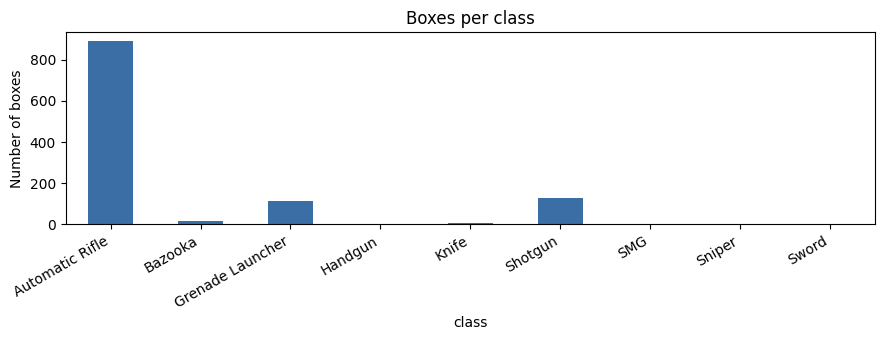

In [7]:
# Class distribution: how many images and how many boxes per class?
img_count = Counter()
box_count = Counter()
for r in records:
    for c in {row[0] for row in r["rows"]}:
        img_count[c] += 1
    for row in r["rows"]:
        box_count[row[0]] += 1

dist = pd.DataFrame({
    "class_id": range(NC),
    "class": CLASS_NAMES,
    "images": [img_count[i] for i in range(NC)],
    "boxes":  [box_count[i] for i in range(NC)],
})
display(dist)

ax = dist.plot.bar(x="class", y="boxes", legend=False, figsize=(9, 3.5), color="#3b6ea5")
ax.set_ylabel("Number of boxes"); ax.set_title("Boxes per class")
plt.xticks(rotation=30, ha="right"); plt.tight_layout(); plt.show()

empty = dist[dist["images"] == 0]["class"].tolist()
if empty:
    print("WARNING: no examples for:", empty, "- the class order may differ from the dataset page.")

### Check the labels against `metadata.csv`

`metadata.csv` stores a class `target` for each file. If the class ids inside the `.txt` labels disagree with it, the model would learn wrong class names, which is a silent and serious problem. Another public project built on this dataset reported having to correct class ids using this metadata file, so it is worth a quick check. This cell only **reports**; it changes nothing.

In [8]:
try:
    if meta is None or "target" not in meta.columns:
        print("Skipped: metadata.csv with a 'target' column was not found.")
    else:
        stem_to_primary = {r["image"].stem: r["primary"] for r in records}

        # find which metadata column holds the file names / ids
        def to_keys(col):
            return meta[col].astype(str).map(lambda s: Path(s).stem)

        best_col, best_overlap = None, 0
        for col in meta.columns:
            if col == "target":
                continue
            overlap = int(to_keys(col).isin(stem_to_primary).sum())
            if overlap > best_overlap:
                best_col, best_overlap = col, overlap

        if best_col is None or best_overlap < 0.5 * len(meta):
            print("Skipped: could not reliably match metadata rows to image file names.")
        else:
            pairs = [(stem_to_primary[k], int(t)) for k, t in zip(to_keys(best_col), meta["target"])
                     if k in stem_to_primary]
            mismatch = sum(a != b for a, b in pairs)
            print(f"Compared {len(pairs)} images using metadata column '{best_col}'.")
            print(f"Label class differs from metadata 'target': {mismatch} ({mismatch / max(len(pairs), 1):.1%})")
            if mismatch / max(len(pairs), 1) > 0.05:
                print("High mismatch: inspect a few of these images before trusting the class names.")
except Exception as err:
    print("Metadata check skipped:", repr(err))

Compared 714 images using metadata column 'imagefile'.
Label class differs from metadata 'target': 640 (89.6%)
High mismatch: inspect a few of these images before trusting the class names.


## Step 6 – Create the train / validation / test split

- **Train**: used to update the model weights.
- **Validation**: used during training to pick the best checkpoint and stop early.
- **Test**: never touched until the end, so it gives an honest estimate of performance on new images.

The split is stratified by each image's main class so every weapon type appears in all three parts, and it is seeded, so the same split is produced every run.

In [9]:
def stratified_split(idx, strata, test_size):
    try:
        return train_test_split(idx, test_size=test_size, random_state=SEED, stratify=strata)
    except ValueError:
        print("  (a class is too small to stratify; falling back to a random split for this step)")
        return train_test_split(idx, test_size=test_size, random_state=SEED)

idx = np.arange(len(records))
primary = np.array([r["primary"] for r in records])

train_idx, temp_idx = stratified_split(idx, primary, SPLIT[1] + SPLIT[2])
val_idx, test_idx   = stratified_split(temp_idx, primary[temp_idx], SPLIT[2] / (SPLIT[1] + SPLIT[2]))
splits = {"train": train_idx, "val": val_idx, "test": test_idx}

# Write a clean copy of the dataset in the layout YOLO expects.
if DATA_DIR.exists():
    shutil.rmtree(DATA_DIR)

for split, ids in splits.items():
    (DATA_DIR / split / "images").mkdir(parents=True)
    (DATA_DIR / split / "labels").mkdir(parents=True)
    for i in ids:
        r = records[i]
        stem = f"{i:04d}_" + re.sub(r"[^A-Za-z0-9_.-]", "_", r["image"].stem)
        shutil.copy2(r["image"], DATA_DIR / split / "images" / (stem + r["image"].suffix.lower()))
        with open(DATA_DIR / split / "labels" / (stem + ".txt"), "w") as f:
            for c, x, y, w, h in r["rows"]:
                f.write(f"{c} {x:.6f} {y:.6f} {w:.6f} {h:.6f}\n")

summary = pd.DataFrame({s: Counter(primary[ids]) for s, ids in splits.items()}).fillna(0).astype(int).sort_index()
summary.index = [CLASS_NAMES[i] for i in summary.index]
summary.loc["TOTAL images"] = summary.sum()
display(summary)

  (a class is too small to stratify; falling back to a random split for this step)
  (a class is too small to stratify; falling back to a random split for this step)


,train,val,test
Automatic Rifle,359,83,89
Bazooka,3,1,0
Grenade Launcher,72,8,8
Handgun,1,0,1
Knife,0,1,0
Shotgun,64,14,10
TOTAL images,499,107,108


## Step 7 – Write the dataset YAML

The YAML tells YOLO where each split lives and what the classes are called. The class names come straight from the dataset page.

In [10]:
DATA_YAML = DATA_DIR / "data.yaml"
data_cfg = {
    "path": str(DATA_DIR),
    "train": "train/images",
    "val": "val/images",
    "test": "test/images",
    "names": {i: n for i, n in enumerate(CLASS_NAMES)},
}
with open(DATA_YAML, "w") as f:
    yaml.safe_dump(data_cfg, f, sort_keys=False)

print(DATA_YAML.read_text())

path: /content/weapon_yolo
train: train/images
val: val/images
test: test/images
names:
  0: Automatic Rifle
  1: Bazooka
  2: Grenade Launcher
  3: Handgun
  4: Knife
  5: Shotgun
  6: SMG
  7: Sniper
  8: Sword



## Step 8 – Preview annotated training images

A quick visual check that boxes line up with the objects and that class names look right. If boxes are clearly misplaced, stop and re-check the labels before training.

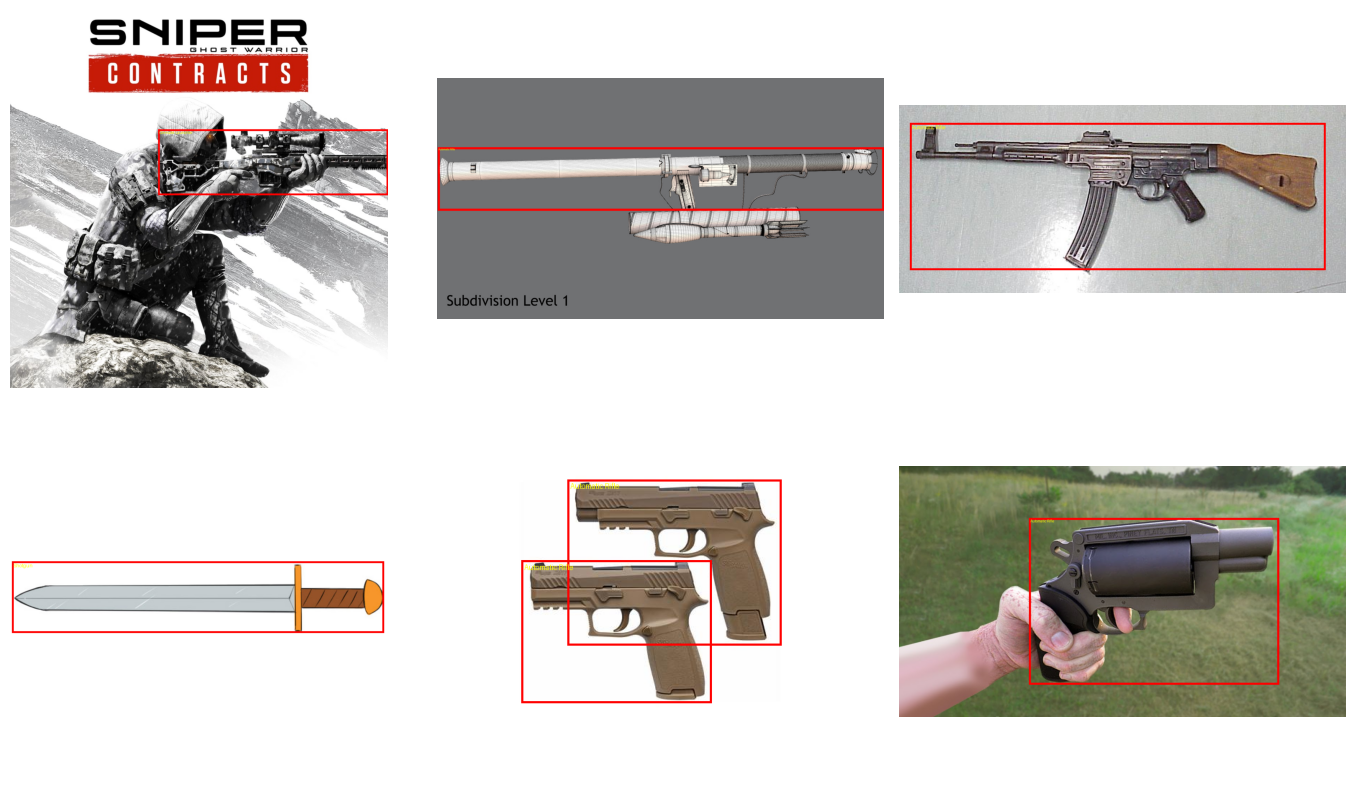

In [11]:
def draw_boxes(img_path, label_path):
    im = Image.open(img_path).convert("RGB")
    W, H = im.size
    d = ImageDraw.Draw(im)
    for line in label_path.read_text().splitlines():
        c, x, y, w, h = line.split()
        c, x, y, w, h = int(c), float(x), float(y), float(w), float(h)
        x1, y1, x2, y2 = (x - w / 2) * W, (y - h / 2) * H, (x + w / 2) * W, (y + h / 2) * H
        d.rectangle([x1, y1, x2, y2], outline="red", width=max(2, W // 200))
        d.text((x1 + 3, y1 + 3), CLASS_NAMES[c], fill="yellow")
    return im

train_imgs = sorted((DATA_DIR / "train" / "images").iterdir())
sample = random.sample(train_imgs, min(6, len(train_imgs)))

fig, axes = plt.subplots(2, 3, figsize=(14, 8))
for ax, p in zip(axes.ravel(), sample):
    ax.imshow(draw_boxes(p, DATA_DIR / "train" / "labels" / (p.stem + ".txt")))
    ax.axis("off")
plt.tight_layout(); plt.show()

## Step 9 – Load a pretrained YOLOv8 model

We start from COCO-pretrained weights. This is **transfer learning**: the network already knows general visual features (edges, shapes, textures) and only has to adapt to our 9 weapon classes. That matters a lot with a dataset of only about 700 images.

In [12]:
model = YOLO(MODEL_WEIGHTS)
print(f"Loaded {MODEL_WEIGHTS}")

Loaded yolov8s.pt


## Step 10 – Train the model

- `data`: the dataset YAML.
- `epochs` / `patience`: maximum epochs, and early stopping if validation stops improving.
- `imgsz`, `batch`: image size and batch size.
- `seed`: makes the run repeatable (Ultralytics also enables deterministic mode by default).
- `cache`: keeps the (small) dataset in RAM for faster epochs.
- Ultralytics applies data augmentation by default (mosaic, flips, colour jitter, scaling), which helps a small dataset generalise.

Watch the validation `mAP50` as it trains. If it is still rising when training ends, increase `EPOCHS`.

In [13]:
results = model.train(
    data=str(DATA_YAML),
    epochs=EPOCHS,
    patience=PATIENCE,
    imgsz=IMGSZ,
    batch=BATCH,
    device=DEVICE,
    seed=SEED,
    cache=True,
    project=str(RUNS_DIR),
    name="weapon_yolov8",
    exist_ok=True,
    plots=True,
)

SAVE_DIR = Path(model.trainer.save_dir)
BEST_PT  = SAVE_DIR / "weights" / "best.pt"
print("Run folder   :", SAVE_DIR)
print("Best weights :", BEST_PT, "| exists:", BEST_PT.exists())

Ultralytics 8.4.215 🚀 Python-3.13.16 torch-2.14.1+cu130 CUDA:0 (Tesla T4, 14913MiB)
engine/trainer: agnostic_nms=False, amp=True, angle=1.0, augment=False, auto_augment=randaugment, batch=16, bgr=0.0, box=7.5, cache=True, cfg=None, channels_last=None, classes=None, close_mosaic=10, cls=0.5, cls_pw=0.0, cls_remap=True, compile=False, conf=None, copy_paste=0.0, copy_paste_mode=flip, cos_lr=False, cutmix=0.0, data=/content/weapon_yolo/data.yaml, degrees=0.0, deterministic=True, device=0, dfl=1.5, dgrad=0.5, dis=6.0, distill_model=None, dlam=1.0, dlog=1.0, dnn=False, dropout=0.0, dynamic=False, embed=None, epochs=60, erasing=0.4, exist_ok=True, fliplr=0.5, flipud=0.0, format=torchscript, fraction=1.0, freeze=None, hsv_h=0.015, hsv_s=0.7, hsv_v=0.4, imgsz=640, iou=None, kobj=1.0, line_width=None, lr0=0.01, lrf=0.01, mask_ratio=4, max_det=300, mixup=0.0, mode=train, model=yolov8s.pt, momentum=0.937, mosaic=1.0, multi_scale=0.0, name=weapon_yolov8, nbs=64, nms=None, opset=None, optimize=False

## Step 11 – Review the training curves

- **Loss curves** (`box_loss`, `cls_loss`, `dfl_loss`) should fall. If training loss keeps falling while validation loss rises, the model is overfitting.
- **Confusion matrix** shows which weapon types get mixed up (for example `SMG` vs `Automatic Rifle`) or missed entirely (the "background" row/column).

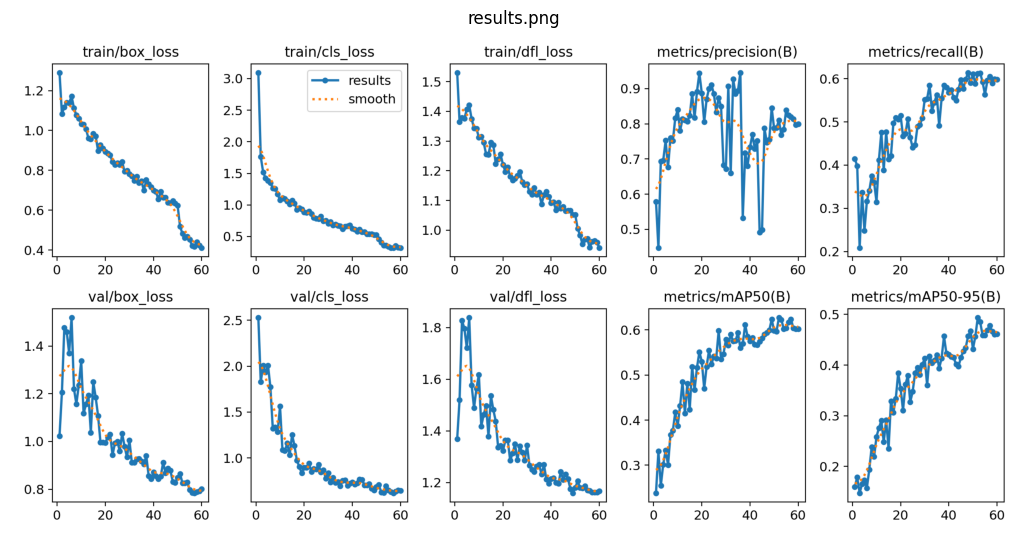

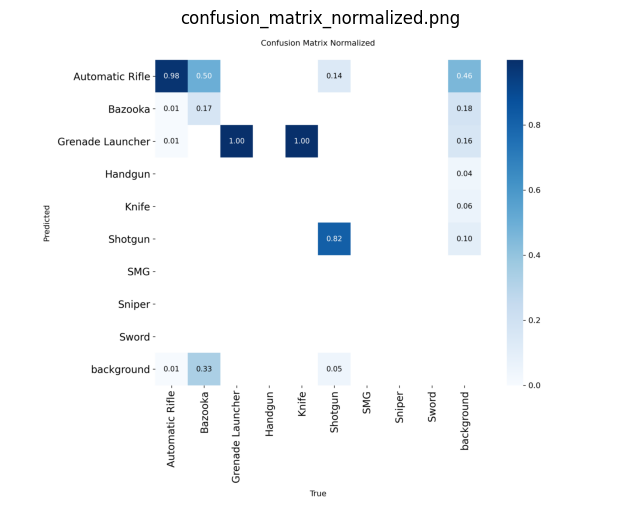

In [14]:
for name in ["results.png", "confusion_matrix_normalized.png"]:
    p = SAVE_DIR / name
    if p.exists():
        plt.figure(figsize=(13, 7) if name == "results.png" else (8, 7))
        plt.imshow(Image.open(p)); plt.axis("off"); plt.title(name); plt.show()

## Step 12 – Evaluate the model

- **Precision:** of the detections made, how many were correct?
- **Recall:** of the real labelled objects, how many did the model find?
- **mAP50:** mean average precision at IoU 0.50 (a detection counts if its box overlaps the true box by at least 50%).
- **mAP50-95:** the same averaged over IoU 0.50 to 0.95, a stricter measure of box accuracy.

We evaluate on the **validation** split (used to choose the checkpoint, so slightly optimistic) and on the **test** split (never used during training, so this is the number to report).

In [15]:
best_model = YOLO(str(BEST_PT))

def evaluate(split):
    return best_model.val(
        data=str(DATA_YAML), split=split, imgsz=IMGSZ, batch=BATCH, device=DEVICE,
        project=str(RUNS_DIR), name=f"eval_{split}", exist_ok=True, plots=(split == "test"),
    )

val_metrics  = evaluate("val")
test_metrics = evaluate("test")

overall = pd.DataFrame({
    "Precision": [val_metrics.box.mp,   test_metrics.box.mp],
    "Recall":    [val_metrics.box.mr,   test_metrics.box.mr],
    "mAP50":     [val_metrics.box.map50, test_metrics.box.map50],
    "mAP50-95":  [val_metrics.box.map,  test_metrics.box.map],
}, index=["validation", "test"]).round(3)
display(overall)

Ultralytics 8.4.215 🚀 Python-3.13.16 torch-2.14.1+cu130 CUDA:0 (Tesla T4, 14913MiB)
Model summary (fused): 72 layers, 11,129,067 parameters, 0 gradients, 28.4 GFLOPs
val: Fast image access ✅ (ping: 0.0±0.0 ms, read: 338.8±725.8 MB/s, size: 98.0 KB)
val: Scanning /content/weapon_yolo/val/labels.cache... 107 images, 0 backgrounds, 0 corrupt: 100% ━━━━━━━━━━━━ 107/107 32.1Mit/s 0.0s
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 7/7 1.9it/s 3.7s
                   all        107        199      0.913      0.569      0.621      0.491
       Automatic Rifle         84        162      0.886       0.86      0.934      0.722
               Bazooka          4          6       0.88      0.167      0.263      0.226
      Grenade Launcher          8          8      0.859          1      0.995      0.837
                 Knife          1          1          1          0     0.0226     0.0158
               Shotgun         14         22   

,Precision,Recall,mAP50,mAP50-95
validation,0.913,0.569,0.621,0.491
test,0.954,0.442,0.464,0.355


In [16]:
# Per-class results on the TEST split
bx = test_metrics.box
per_class = pd.DataFrame({
    "class": [CLASS_NAMES[i] for i in bx.ap_class_index],
    "AP50": bx.ap50,
    "AP50-95": bx.ap,
}).round(3).sort_values("AP50", ascending=False).reset_index(drop=True)
display(per_class)

missing = [c for c in CLASS_NAMES if c not in set(per_class["class"])]
if missing:
    print("No test examples for:", missing)

,class,AP50,AP50-95
0,Grenade Launcher,0.995,0.807
1,Automatic Rifle,0.940,0.745
2,Shotgun,0.810,0.542
3,Handgun,0.041,0.037
4,Bazooka,0.000,0.000
5,Knife,0.000,0.000


No test examples for: ['SMG', 'Sniper', 'Sword']


## Step 13 – Predictions on unseen test images

These images were never used for training or checkpoint selection. A **confidence score** is the model's own estimate for a prediction. It is not proof that the object is really a weapon.

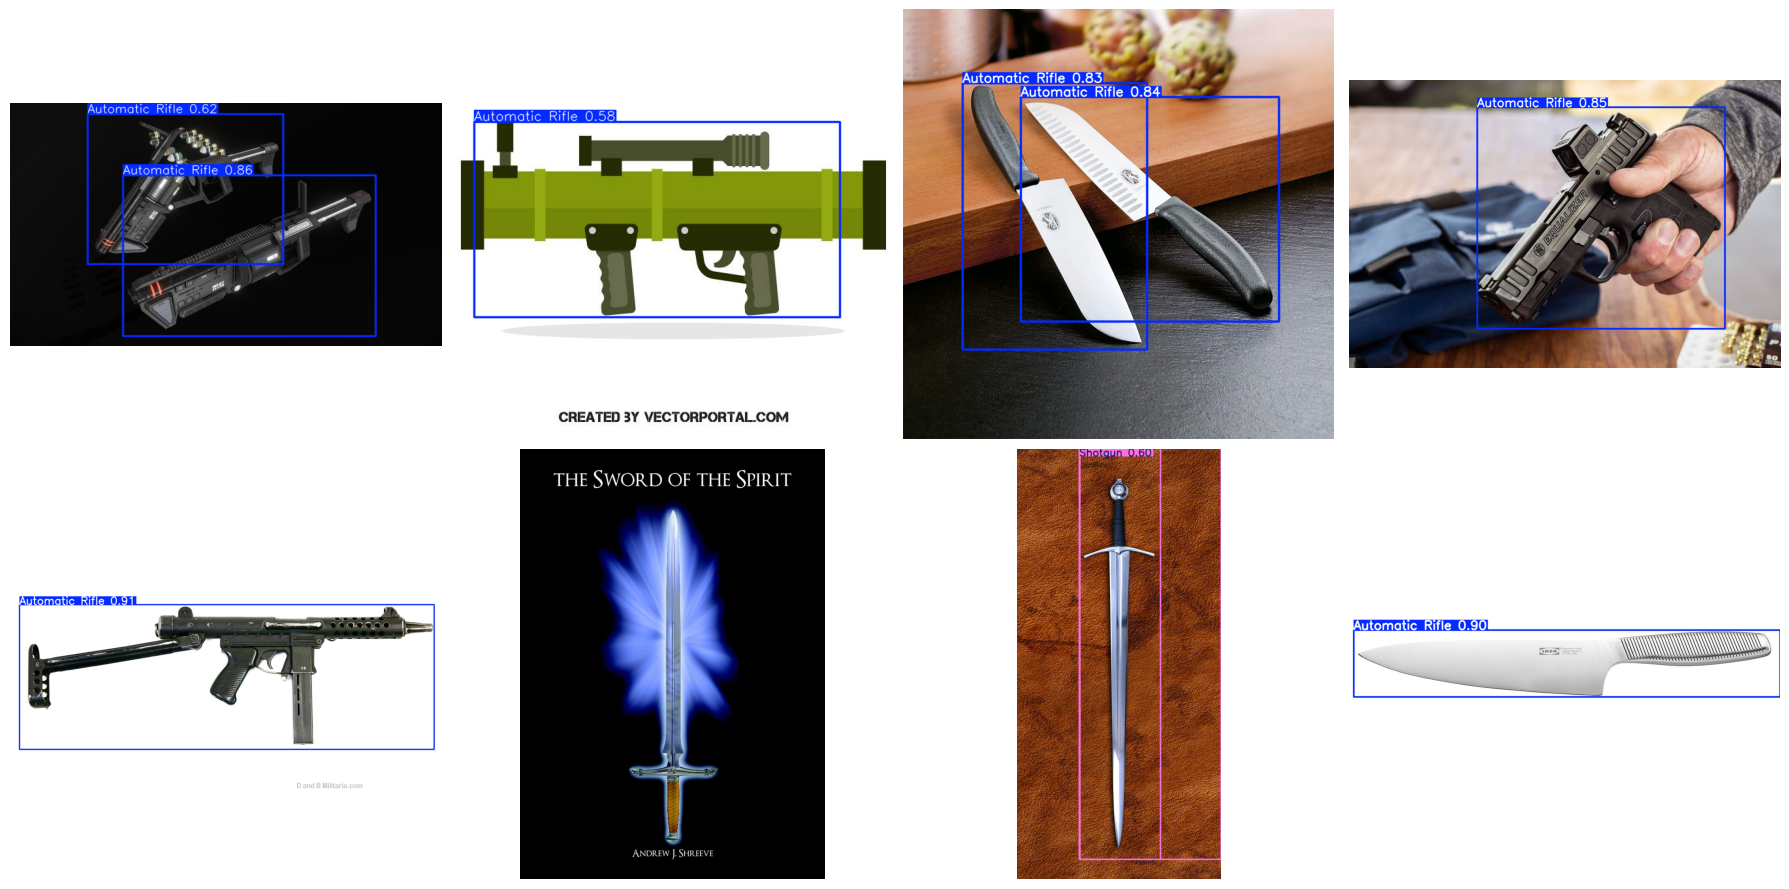

In [17]:
test_imgs = sorted((DATA_DIR / "test" / "images").iterdir())
sample = random.sample(test_imgs, min(8, len(test_imgs)))

preds = best_model.predict(
    source=[str(p) for p in sample], conf=CONF_THRES, imgsz=IMGSZ, device=DEVICE, verbose=False
)

fig, axes = plt.subplots(2, 4, figsize=(18, 9))
for ax, r in zip(axes.ravel(), preds):
    ax.imshow(r.plot()[..., ::-1])      # Ultralytics returns BGR; convert to RGB
    ax.axis("off")
plt.tight_layout(); plt.show()

### Try your own images (optional, Colab)

Upload any images to see the model's predictions. Outside Colab, set `my_images` to a list of file paths instead.

Saving 2608-22-Robbery-106-Pct-09-14-22-2.jpg to 2608-22-Robbery-106-Pct-09-14-22-2.jpg


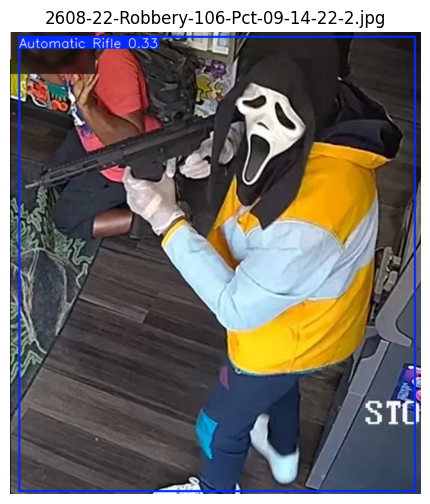

  Automatic Rifle: 0.33


In [18]:
if IN_COLAB:
    from google.colab import files
    up = files.upload()
    my_images = [n for n in up if Path(n).suffix.lower() in IMG_EXT]
else:
    my_images = []          # e.g. ["photo1.jpg", "photo2.png"]

my_preds = best_model.predict(source=my_images, conf=CONF_THRES, imgsz=IMGSZ, device=DEVICE, verbose=False) if my_images else []
for r in my_preds:
    plt.figure(figsize=(8, 6)); plt.imshow(r.plot()[..., ::-1]); plt.axis("off")
    plt.title(Path(r.path).name); plt.show()
    for box in r.boxes:
        print(f"  {CLASS_NAMES[int(box.cls)]}: {float(box.conf):.2f}")

if not my_images:
    print("No custom images provided.")

## Step 14 – Save the model and the results

`best.pt` holds the weights of the best validation checkpoint. Keep it to reuse the model without retraining. For GitHub, avoid committing the large model file unless your repository allows it, and describe how to download it instead.

In [19]:
OUT_DIR = WORK_DIR / "weapon_yolov8_outputs"
OUT_DIR.mkdir(exist_ok=True)

shutil.copy2(BEST_PT, OUT_DIR / "weapon_yolov8_best.pt")
overall.to_csv(OUT_DIR / "overall_metrics.csv")
per_class.to_csv(OUT_DIR / "per_class_test_metrics.csv", index=False)
shutil.copy2(DATA_YAML, OUT_DIR / "data.yaml")

print("Saved to:", OUT_DIR)
print("\nCopy these numbers into your report (they come from YOUR run):\n")
print(overall.to_string())

Saved to: /content/weapon_yolov8_outputs

Copy these numbers into your report (they come from YOUR run):

            Precision  Recall  mAP50  mAP50-95
validation      0.913   0.569  0.621     0.491
test            0.954   0.442  0.464     0.355


In [20]:
# Optional: export for deployment (ONNX runs without PyTorch).
# best_model.export(format="onnx", imgsz=IMGSZ)

if IN_COLAB:
    from google.colab import files
    files.download(str(OUT_DIR / "weapon_yolov8_best.pt"))

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

## Step 15 – Project conclusion

In this project, we:
1. Downloaded the Kaggle Weapon Detection Dataset (714 images, 9 weapon classes, YOLO labels).
2. Validated every label file and checked the class distribution.
3. Built a reproducible, stratified train / validation / test split.
4. Fine-tuned a pretrained YOLOv8 model on the training split.
5. Evaluated it overall and per class on validation and on a held-out test split.
6. Ran predictions on unseen images and saved the best weights.

### Results
Record the numbers printed in Step 12 here. Do not invent results.

| Split | Precision | Recall | mAP50 | mAP50-95 |
|---|---|---|---|---|
| Validation | | | | |
| Test | | | | |

### Before GitHub submission
- Dataset: *Weapon Detection Dataset* by Snehil Sanyal, https://www.kaggle.com/datasets/snehilsanyal/weapon-detection-test (CC0).
- Include this notebook and a `requirements.txt` (`ultralytics`, `kagglehub`, `scikit-learn`, `pandas`, `matplotlib`, `pyyaml`).
- Explain how to run it: open in Colab, select a GPU runtime, run all cells.
- Report the metrics from your own run, plus a few sample predictions and the confusion matrix.
- Note that Ultralytics YOLOv8 is released under AGPL-3.0, which matters if you plan to distribute a product built on it.

### Important limitations
- **Small dataset.** About 700 images across 9 classes means some classes have few examples, so per-class scores can be noisy and swing noticeably between runs or splits.
- **Look-alike classes.** `Automatic Rifle`, `SMG`, `Sniper`, and `Shotgun` are visually similar, so confusion between them is expected.
- **Possible near-duplicates.** The images were collected from the web, so similar pictures can land in both train and test and make scores look better than they really are.
- **Limited conditions.** Performance on CCTV footage, low light, occlusion, or toys and tools that resemble weapons is not measured here and is likely worse than on this dataset.
- The model may miss real objects or flag harmless ones. This is a project demonstration, not a certified security system, and it should never be the sole basis for a real-world decision.